# Détection de transactions frauduleuses

## 1. Découverte des données

### Objectif
Comprendre la structure du dataset, identifier les variables
et vérifier la qualité initiale des données avant le nettoyage.

In [2]:
import pandas as pd 
df = pd.read_csv(r"C:\Users\PC DOCTOR\Downloads\PS_20174392719_1491204439457_log.csv\PS_20174392719_1491204439457_log.csv")

In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
df.shape

(6362620, 11)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [6]:
df.columns.tolist()

['step',
 'type',
 'amount',
 'nameOrig',
 'oldbalanceOrg',
 'newbalanceOrig',
 'nameDest',
 'oldbalanceDest',
 'newbalanceDest',
 'isFraud',
 'isFlaggedFraud']

## 2. Vérification initiale de la qualité des données

In [7]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["type"].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [10]:
df["type"].value_counts(normalize=True) * 100

type
CASH_OUT    35.166331
PAYMENT     33.814608
CASH_IN     21.992261
TRANSFER     8.375622
DEBIT        0.651178
Name: proportion, dtype: float64

In [11]:
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

## 3. Analyse des fraudes selon le type de transaction

In [12]:
df.groupby(["type", "isFraud"]).size().unstack(fill_value=0)

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [13]:
#le pourcentage de fraudes pour chaque type
df.groupby("type")["isFraud"].mean().mul(100)

type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64

<Axes: title={'center': 'Taux de fraude par type de transaction'}, xlabel='Type de transaction', ylabel='Taux de fraude (%)'>

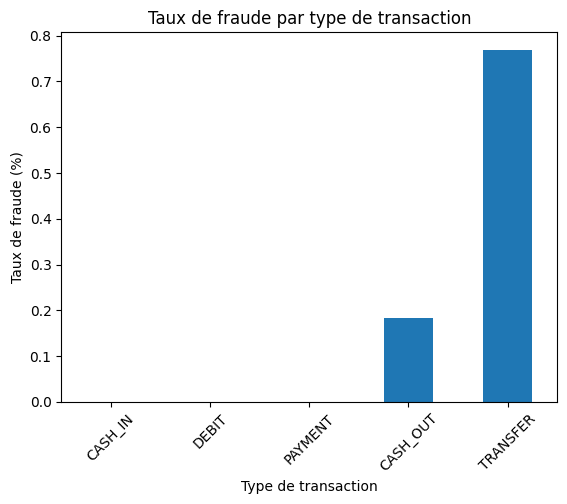

In [14]:
fraud_rate = df.groupby("type")["isFraud"].mean() * 100

fraud_rate.sort_values().plot(
    kind="bar",
    title="Taux de fraude par type de transaction",
    ylabel="Taux de fraude (%)",
    xlabel="Type de transaction",
    rot=45
)

In [15]:
df.dtypes

step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

In [16]:
# verifie les valeurs negatives 
df[["amount", "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest"]].lt(0).sum()

amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
dtype: int64

In [17]:
df["expected_balance_orig"] = (
    df["oldbalanceOrg"] - df["amount"]
)

df["balance_difference_orig"] = (
    df["newbalanceOrig"] - df["expected_balance_orig"]
)

df["balance_difference_orig"].describe()
# Prenons un exemple simple : les écarts sont 0, 0, -50, 0, +50.
# count = 5 : cinq transactions analysées.
#mean = 0 : la moyenne des écarts est nulle.
#min = -50 : le plus grand écart négatif en valeur absolue est ici −50.
#max = +50 : le plus grand écart positif est +50.
#50% = 0 : la médiane est zéro.


count    6.362620e+06
mean     2.010925e+05
std      6.066505e+05
min     -1.000000e-02
25%      2.954230e+03
50%      6.867726e+04
75%      2.496411e+05
max      9.244552e+07
Name: balance_difference_orig, dtype: float64

In [18]:
#Elle comparera les écarts entre les transactions normales (isFraud = 0) et les transactions frauduleuses (isFraud = 1).
df.groupby("isFraud")["balance_difference_orig"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,201338.558109,606928.890826,-1.000000e-02,3034.305,69049.31,249953.43,92445516.64
1,8213.0,10692.325265,265146.131130,-3.725290e-09,0.000,0.00,0.00,10000000.00


In [19]:
print("Répartition de isFraud :")
print(df["isFraud"].value_counts())

print("\nRépartition de isFlaggedFraud :")
print(df["isFlaggedFraud"].value_counts())

Répartition de isFraud :
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Répartition de isFlaggedFraud :
isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64


In [20]:
pd.crosstab(
    df["isFlaggedFraud"],
    df["isFraud"],
    margins=True
)

isFraud,0,1,All
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


In [21]:

print(df.columns.tolist())
df.info()

['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'expected_balance_orig', 'balance_difference_orig']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 13 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   step                     int64  
 1   type                     object 
 2   amount                   float64
 3   nameOrig                 object 
 4   oldbalanceOrg            float64
 5   newbalanceOrig           float64
 6   nameDest                 object 
 7   oldbalanceDest           float64
 8   newbalanceDest           float64
 9   isFraud                  int64  
 10  isFlaggedFraud           int64  
 11  expected_balance_orig    float64
 12  balance_difference_orig  float64
dtypes: float64(7), int64(3), object(3)
memory usage: 631.1+ MB


In [22]:
df.head(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,expected_balance_orig,balance_difference_orig
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,160296.36,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,19384.72,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,0.00,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,0.00,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,29885.86,0.0


## la partie postgsql


In [23]:
df_sample = df.head(1000).copy()

print("Nombre de lignes :", len(df_sample))
print("Nombre de colonnes :", len(df_sample.columns))

Nombre de lignes : 1000
Nombre de colonnes : 13


In [24]:
import psycopg

print("Version de Psycopg :", psycopg.__version__)

Version de Psycopg : 3.3.6


In [25]:
import psycopg

conn = psycopg.connect(
    host="localhost",
    port=5432,
    dbname="postgres",
    user="postgres",
    password="souali2023"
)

print("Connexion réussie !")
conn.close()

OperationalError: connection failed: connection to server at "127.0.0.1", port 5432 failed: FATAL:  password authentication failed for user "postgres"
Multiple connection attempts failed. All failures were:
- host: 'localhost', port: 5432, hostaddr: '::1': connection failed: connection to server at "::1", port 5432 failed: FATAL:  password authentication failed for user "postgres"
- host: 'localhost', port: 5432, hostaddr: '127.0.0.1': connection failed: connection to server at "127.0.0.1", port 5432 failed: FATAL:  password authentication failed for user "postgres"

In [ ]:
import pandas as pd
import psycopg

# Colonnes présentes dans la table PostgreSQL
columns = [
    "step", "type", "amount", "nameOrig",
    "oldbalanceOrg", "newbalanceOrig", "nameDest",
    "oldbalanceDest", "newbalanceDest",
    "isFraud", "isFlaggedFraud"
]

# Vérifier que toutes les colonnes existent
missing = [col for col in columns if col not in df_sample.columns]

if missing:
    raise ValueError(f"Colonnes manquantes dans df_sample : {missing}")

# Préparer les valeurs et convertir les valeurs manquantes en None
data = df_sample[columns].astype(object).where(
    pd.notna(df_sample[columns]), None
)

records = [
    tuple(
        value.item() if hasattr(value, "item") else value
        for value in row
    )
    for row in data.itertuples(index=False, name=None)
]

# Connexion à PostgreSQL
conn = psycopg.connect(
    host="localhost",
    port=5432,
    dbname="payguard_ai",
    user="postgres",
    password="souali2023"
)

try:
    with conn.cursor() as cur:
        query = """
            INSERT INTO transactions (
                step, type, amount, nameOrig,
                oldbalanceOrg, newbalanceOrig, nameDest,
                oldbalanceDest, newbalanceDest,
                isFraud, isFlaggedFraud
            )
            VALUES (
                %s, %s, %s, %s, %s, %s,
                %s, %s, %s, %s, %s
            )
        """

        cur.executemany(query, records)

    conn.commit()
    print(f"Importation réussie : {len(records)} lignes insérées.")

except Exception:
    conn.rollback()
    raise

finally:
    conn.close()

Importation réussie : 1000 lignes insérées.


In [ ]:
import os
print("PGPASSWORD définie :", "PGPASSWORD" in os.environ)

PGPASSWORD définie : False


In [ ]:
import getpass
import psycopg

conn = psycopg.connect(
    host="localhost",
    port=5432,
    dbname="payguard_ai",
    user="postgres",
    password=getpass.getpass("loubna2023")
)
print("Connexion réussie")
conn.close()

Connexion réussie


In [ ]:
import getpass
import io
import pandas as pd
import psycopg

CHEMIN_CSV = r"C:\Users\PC DOCTOR\Downloads\PS_20174392719_1491204439457_log.csv\PS_20174392719_1491204439457_log.csv"
CHUNK = 250_000

colonnes = ["step", "type", "amount", "nameOrig", "oldbalanceOrg",
            "newbalanceOrig", "nameDest", "oldbalanceDest",
            "newbalanceDest", "isFraud", "isFlaggedFraud"]

conn = psycopg.connect(
    host="localhost", port=5432, dbname="payguard_ai",
    user="postgres",
    password=getpass.getpass("Mot de passe PostgreSQL : ")
)

total = 0
try:
    with conn.cursor() as cur:
        for i, chunk in enumerate(pd.read_csv(CHEMIN_CSV, usecols=colonnes, chunksize=CHUNK), start=1):
            chunk = chunk[colonnes]
            buffer = io.StringIO()
            chunk.to_csv(buffer, index=False, header=False)
            buffer.seek(0)

            with cur.copy("COPY public.transactions_full FROM STDIN WITH (FORMAT csv)") as copy:
                copy.write(buffer.read())

            total += len(chunk)
            print(f"Bloc {i} : {total:,} lignes chargées")
    conn.commit()
    print("Chargement terminé.")
except Exception:
    conn.rollback()
    raise
finally:
    conn.close()

Bloc 1 : 250,000 lignes chargées
Bloc 2 : 500,000 lignes chargées
Bloc 3 : 750,000 lignes chargées
Bloc 4 : 1,000,000 lignes chargées
Bloc 5 : 1,250,000 lignes chargées
Bloc 6 : 1,500,000 lignes chargées
Bloc 7 : 1,750,000 lignes chargées
Bloc 8 : 2,000,000 lignes chargées
Bloc 9 : 2,250,000 lignes chargées
Bloc 10 : 2,500,000 lignes chargées
Bloc 11 : 2,750,000 lignes chargées
Bloc 12 : 3,000,000 lignes chargées
Bloc 13 : 3,250,000 lignes chargées
Bloc 14 : 3,500,000 lignes chargées
Bloc 15 : 3,750,000 lignes chargées
Bloc 16 : 4,000,000 lignes chargées
Bloc 17 : 4,250,000 lignes chargées
Bloc 18 : 4,500,000 lignes chargées
Bloc 19 : 4,750,000 lignes chargées
Bloc 20 : 5,000,000 lignes chargées
Bloc 21 : 5,250,000 lignes chargées
Bloc 22 : 5,500,000 lignes chargées
Bloc 23 : 5,750,000 lignes chargées
Bloc 24 : 6,000,000 lignes chargées
Bloc 25 : 6,250,000 lignes chargées
Bloc 26 : 6,362,620 lignes chargées
Chargement terminé.


## entrainement des modele


In [ ]:
import getpass
import pandas as pd
import psycopg

conn = psycopg.connect(
    host="localhost", port=5432, dbname="payguard_ai",
    user="postgres",
    password=getpass.getpass("loubna2023")
)

query = """
SELECT
    step,
    transaction_type,
    amount,
    old_balance_orig,
    new_balance_orig,
    old_balance_dest,
    new_balance_dest,
    orig_balance_mismatch,
    dest_balance_mismatch,
    is_fraud
FROM silver.transactions_clean
WHERE transaction_type IN ('CASH_OUT', 'TRANSFER')
"""

df_model = pd.read_sql(query, conn)
conn.close()

print(df_model.shape)
df_model.head()

C:\Users\PC DOCTOR\AppData\Local\Temp\ipykernel_14436\1520627242.py:27: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_model = pd.read_sql(query, conn)


(2770409, 10)


,step,transaction_type,amount,old_balance_orig,new_balance_orig,old_balance_dest,new_balance_dest,orig_balance_mismatch,dest_balance_mismatch,is_fraud
0,1,TRANSFER,181.00,181.0,0.0,0.0,0.00,0,1,1
1,1,CASH_OUT,181.00,181.0,0.0,21182.0,0.00,0,1,1
2,1,CASH_OUT,229133.94,15325.0,0.0,5083.0,51513.44,1,1,0
3,1,TRANSFER,215310.30,705.0,0.0,22425.0,0.00,1,1,0
4,1,TRANSFER,311685.89,10835.0,0.0,6267.0,2719172.89,1,1,0


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, average_precision_score

# 1. Variables du modèle A (sans les indicateurs d'écart)
X = df_model[["step", "amount", "old_balance_orig", "new_balance_orig",
              "old_balance_dest", "new_balance_dest"]].copy()
X["is_transfer"] = (df_model["transaction_type"] == "TRANSFER").astype(int)
y = df_model["is_fraud"]

# 2. Séparation par temps
masque_train = df_model["step"] <= 600
X_train, y_train = X[masque_train], y[masque_train]
X_test,  y_test  = X[~masque_train], y[~masque_train]

# 3. Choix du modèle + entraînement (fit sur le train seulement)
modele = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)
modele.fit(X_train, y_train)

# 4. Évaluation sur le test
y_pred = modele.predict(X_test)
y_score = modele.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred, digits=3))
print("PR-AUC :", round(average_precision_score(y_test, y_score), 3))

              precision    recall  f1-score   support

           0      0.998     0.866     0.927     41950
           1      0.212     0.947     0.347      1600

    accuracy                          0.869     43550
   macro avg      0.605     0.906     0.637     43550
weighted avg      0.969     0.869     0.906     43550

PR-AUC : 0.806


In [30]:
X_b = X.copy()
X_b["orig_balance_mismatch"] = df_model["orig_balance_mismatch"]
X_b["dest_balance_mismatch"] = df_model["dest_balance_mismatch"]

X_train_b, X_test_b = X_b[masque_train], X_b[~masque_train]

modele_b = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)
modele_b.fit(X_train_b, y_train)

y_pred_b = modele_b.predict(X_test_b)
y_score_b = modele_b.predict_proba(X_test_b)[:, 1]
print(classification_report(y_test, y_pred_b, digits=3))
print("PR-AUC :", round(average_precision_score(y_test, y_score_b), 3))

              precision    recall  f1-score   support

           0      1.000     0.891     0.943     41950
           1      0.260     0.999     0.412      1600

    accuracy                          0.895     43550
   macro avg      0.630     0.945     0.677     43550
weighted avg      0.973     0.895     0.923     43550

PR-AUC : 0.885
